# Module 8 Lab 1: AI-Assisted EDA, Verified

## 1. Load the penguins data

In [12]:

import pandas as pd

df = pd.read_csv("penguins.csv")
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
...,...,...,...,...,...,...,...,...
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009


## 2.Establish ground truth by hand, no AI


In [13]:
df.shape

(344, 8)

In [14]:
df.isnull().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


In [15]:
df["species"].value_counts()

,count
species,
Adelie,152
Gentoo,124
Chinstrap,68


### Ground Truth Summary
The results look plausible - he dataset has 344 rows and 8 columns, the species counts (Adelie 152, Gentoo 124, and Chinstrap 68) add up to 344, matching the total number of rows.
We also observe missing values: 2 in each of the four measurement columns and 11 in the sex column. The remaining columns have no missing values.

## 3.Prompt the AI (and log it).

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


### Prompt Log

AI Tool Used: ChatGPT
Full Prompt:
I am performing exploratory data analysis in Google Colab and would like your assistance with Python code using pandas and seaborn. My DataFrame is named df.
The dataset contains 344 rows and 8 columns with the following names and data types:
- species: object
- island: object
- bill_length_mm: float64
- bill_depth_mm: float64
- flipper_length_mm: float64
- body_mass_g: float64
- sex: object
- year: int64
Write  Python code using pandas and seaborn to:
1. Summarize the missing values in each column.
2. Compare the mean flipper length (flipper_length_mm) across penguin species (species).
3.Give one clearly labeled chart comparing flipper length across species.
Explain each step in code comments.
Do not modify the original DataFrame, fill missing values, or remove rows without explaining why.

 ### Verification (Step 5): My independent groupby calculation confirmed all three AI-generated mean flipper lengths, with no mismatches or corrections needed; the detailed comparison is presented in Step 5.

## 4. Run the AI’s code

In [17]:
# Summarize missing values in each column
missing_summary = df.isnull().sum()
print("Missing values by column:")
print(missing_summary)

Missing values by column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64


In [18]:
# Calculate the mean flipper length for each penguin species
mean_flipper = df.groupby("species")["flipper_length_mm"].mean()

# Display the mean flipper length by species
print("Mean flipper length by species (mm):")
print(mean_flipper)

Mean flipper length by species (mm):
species
Adelie       189.953642
Chinstrap    195.823529
Gentoo       217.186992
Name: flipper_length_mm, dtype: float64


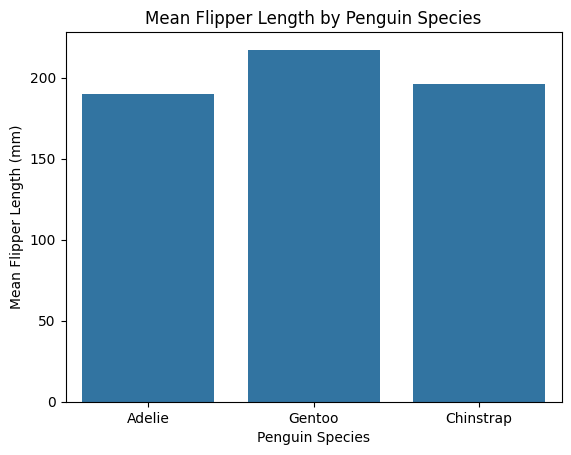

In [19]:
# Import seaborn and matplotlib for visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Create a chart comparing mean flipper length across species
sns.barplot(data=df, x="species", y="flipper_length_mm", errorbar=None)

# Add a descriptive title and axis labels
plt.title("Mean Flipper Length by Penguin Species")
plt.xlabel("Penguin Species")
plt.ylabel("Mean Flipper Length (mm)")

# Display the chart
plt.show()

## 5. The verification checkpoint

In [20]:
df.groupby("species")["flipper_length_mm"].mean()

,flipper_length_mm
species,
Adelie,189.953642
Chinstrap,195.823529
Gentoo,217.186992


## Verification Result
I independently calculated the mean flipper length for each penguin species using one groupby line, I compared my results with the AI-generated values
The results matched for all three species: Adelie (189.953642 mm), Chinstrap (195.823529 mm), and Gentoo (217.186992 mm).
There were no differences between the two calculations. The dataset contains two missing values in the flipper_length_mm column, as identified in Step 2. Pandas automatically excludes missing measurements when calculating the mean, so these values did not affect the averages. Both calculations used the original dataset without filling missing values or deleting rows.
Conclusion: The AI-generated results were confirmed by my calculation. No corrections were necessary.

## 6. One follow-up, one judgment

### AI Follow-up Prompt

Can you improve my existing seaborn bar chart by displaying the mean flipper length above each species bar, rounded to one decimal place? Keep clear labels, add code comments, and do not modify the original DataFrame.

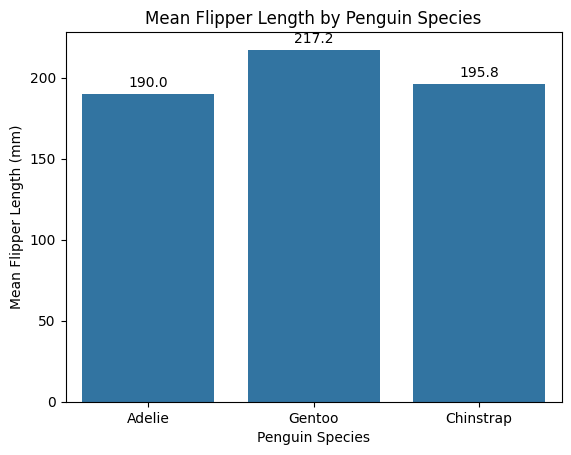

In [21]:
# Import libraries for visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Create a bar chart of mean flipper length by species
ax = sns.barplot(
    data=df,
    x="species",
    y="flipper_length_mm",
    errorbar=None
)

# Add the mean value above each bar, rounded to one decimal place
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.1f}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 3),
        textcoords="offset points"
    )

# Add a clear title and axis labels
plt.title("Mean Flipper Length by Penguin Species")
plt.xlabel("Penguin Species")
plt.ylabel("Mean Flipper Length (mm)")

# Display the improved chart
plt.show()

### Judgment
The numerical labels make it easier to compare the mean flipper lengths without estimating values from the vertical axis.

## 7. My Own Insight (No AI)

### My Question
Is there a relationship between penguin flipper length and the island where the penguins were observed?

In [22]:
# Calculate mean flipper length for each island using the groupby method from Step 5
df.groupby("island")["flipper_length_mm"].mean()

,flipper_length_mm
island,
Biscoe,209.706587
Dream,193.072581
Torgersen,191.196078


### My Insight
On Biscoe Island, penguins have a longer average flipper length than penguins on Dream and Torgersen Islands. The difference between Biscoe and Torgersen Islands is approximately 18.5 mm.
However, this difference may be related to the penguin species living on each island rather than to the natural characteristics of the islands themselves.

## 8. Privacy Reflection
###
Unlike the public penguin dataset, some sensitive data from my workplace may contain private information, such as names, IDs, and individual records, which I would never paste into a public AI tool. Instead, I would use anonymized or aggregated data. This would help protect customer privacy while still providing useful information for analysis.